In [1]:
import pandas as pd 
import matplotlib.pyplot as plt
df_2022 = pd.read_csv("/home/priyansh_jain01/workspace/Air_quality_project/data/raw/2022.csv")
df_2023 = pd.read_csv("/home/priyansh_jain01/workspace/Air_quality_project/data/raw/2023.csv")
df_2024 = pd.read_csv("/home/priyansh_jain01/workspace/Air_quality_project/data/raw/2024.csv")
df_2025 = pd.read_csv("/home/priyansh_jain01/workspace/Air_quality_project/data/raw/2025.csv")

combined_df = pd.concat(
    [df_2022, df_2023, df_2024, df_2025],
    ignore_index=True
)


combined_df["Timestamp"] = pd.to_datetime(
    combined_df["Timestamp"],
    format="mixed"
)


combined_df["Year"] = combined_df["Timestamp"].dt.year
combined_df["Month"] = combined_df["Timestamp"].dt.month
combined_df["Month_Name"] = combined_df["Timestamp"].dt.month_name()


cleaned_df = combined_df.copy()

cleaned_df = cleaned_df.dropna(axis=1, how="all")

cleaned_df = cleaned_df.drop(columns=["TOT-RF (mm)"])

cleaned_df.shape

(1461, 21)

In [2]:
Q1 = cleaned_df["PM2.5 (µg/m³)"].quantile(0.25)
Q3 = cleaned_df["PM2.5 (µg/m³)"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: 55.14868055555556
Q3: 175.07999999999998
IQR: 119.93131944444443
Lower Bound: -124.7482986111111
Upper Bound: 354.97697916666664


In [3]:
pm25_outliers = cleaned_df[
    (cleaned_df["PM2.5 (µg/m³)"] < lower_bound) |
    (cleaned_df["PM2.5 (µg/m³)"] > upper_bound)
]

print("Number of potential outliers:", len(pm25_outliers))

Number of potential outliers: 43


In [4]:
pm25_outliers[
    ["Timestamp", "PM2.5 (µg/m³)", "PM10 (µg/m³)", "Year", "Month_Name"]
]

,Timestamp,PM2.5 (µg/m³),PM10 (µg/m³),Year,Month_Name
0,2022-01-01,393.560000,598.820000,2022,January
1,2022-01-02,424.810000,598.950000,2022,January
2,2022-01-03,375.520000,636.120000,2022,January
306,2022-11-03,398.790000,687.220000,2022,November
351,2022-12-18,378.270000,519.880000,2022,December
352,2022-12-19,365.440000,477.480000,2022,December
373,2023-01-09,494.145833,685.093750,2023,January
670,2023-11-02,398.538194,693.798611,2023,November
672,2023-11-04,422.369792,726.473958,2023,November
674,2023-11-06,358.637500,567.803571,2023,November


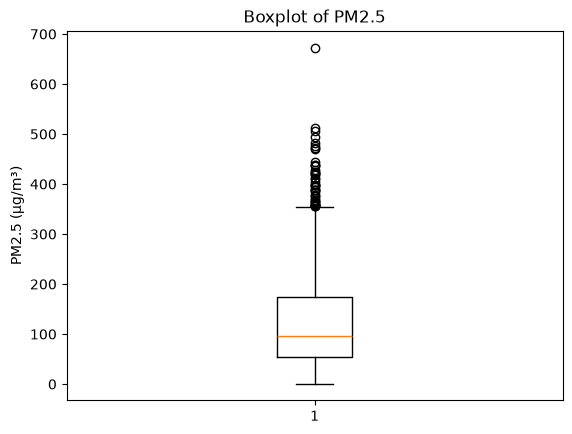

In [ ]:
plt.boxplot(
    cleaned_df["PM2.5 (µg/m³)"].dropna()
)

plt.ylabel("PM2.5 (µg/m³)")
plt.title("Boxplot of PM2.5")
plt.show()

# Final Check 

In [7]:
cleaned_df.shape

(1461, 21)

In [9]:
cleaned_df.isnull().sum().sort_values(ascending=False)

Toluene (µg/m³)    228
Benzene (µg/m³)    226
BP (mmHg)          167
CO (mg/m³)          70
SO2 (µg/m³)         51
NO2 (µg/m³)         46
NO (µg/m³)          46
WS (m/s)            42
NOx (ppb)           41
NH3 (µg/m³)         41
Ozone (µg/m³)       39
PM10 (µg/m³)        38
PM2.5 (µg/m³)       34
WD (deg)            34
AT (°C)             33
RH (%)              33
SR (W/mt2)          30
Timestamp            0
Year                 0
Month                0
Month_Name           0
dtype: int64

In [12]:
print("Duplicate rows:", cleaned_df.duplicated().sum())

print(
    "Duplicate timestamps:",
    cleaned_df["Timestamp"].duplicated().sum()
)

Duplicate rows: 0
Duplicate timestamps: 0


In [13]:
print("Start:", cleaned_df["Timestamp"].min())
print("End:", cleaned_df["Timestamp"].max())

Start: 2022-01-01 00:00:00
End: 2025-12-31 00:00:00


In [14]:
cleaned_df.to_csv(
    "../data/cleaned/air_quality_cleaned_2022_2025.csv",
    index=False
)